# 07 Funnel Dropoff

**Question:** Where do we lose volume, and in which segments?

Task 2, step 7: **map the funnel drop-off: where volume is lost at each step, and which segments lose the most.**

The funnel has three steps, each with its own loss:

| Step | Kept | Lost | Rate |
|---|---|---|---|
| bid → impression | auctions won | auctions lost | win rate |
| impression → click | clicked impressions | impressions nobody clicked | CTR |
| click → conversion | post-click conversions | clicks that didn't convert | CVR |

**Which segments lose the most?** A low rate alone isn't enough: a tiny segment with a bad rate loses little volume. For every segment, the notebook compares what it actually passed to the next step with what it **would have passed at its campaign's average rate**:

`shortfall = segment input × campaign rate − segment output`

A positive shortfall means the segment loses **more than its share**. `z = shortfall / sqrt(input × rate × (1 − rate))` says whether that is more than noise. Segments are compared **within their own campaign**, because campaigns have very different rates (pooling them is the Simpson's-paradox trap of Notebook 09).

The setup, user-agent parsing, click linking and segment aggregation are the same code as Notebook 05. The database is opened read-only.

### Setup

In [5]:
# CELL 1: setup (read-only connection)
from pathlib import Path
import math, os, re, shutil, signal, time
import duckdb
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

pd.set_option("display.max_rows", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

KILL_STALE = False
RUN_WIN_RATE = True          # win rate needs one pass over the 53M bids (a few minutes)
FOCUS = 1458                 # the campaign shown in detail; change to any advertiser_id
MIN_EXPECTED_CLICKS = 30     # CTR shown when imps >= this / overall CTR
MIN_CLICKS_CVR, MIN_CONVS_CPA, MIN_BIDS_WR = 30, 10, 1_000
TOP_TAGS = 30                # user tags shown (by volume)
PROJECT_ROOT = Path.cwd().parent
# Where the data comes from (the views raw_* and typed_* are the same either way):
#   1. data/processed/ipinyou.duckdb, the database the loading notebook built, if it is still there
#   2. otherwise the pipeline's hourly Parquet files in data/interim, read in memory (pipeline_views.py)
DB_PATH = PROJECT_ROOT / "data" / "processed" / "ipinyou.duckdb"
BID_DIR = PROJECT_ROOT / "data" / "interim" / "bid_parquet"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"

if "con" in globals():
    try:
        con.close()
    except Exception:
        pass

def open_db(path, kill_stale=False, retries=5):
    for attempt in range(retries):
        try:
            return duckdb.connect(str(path), read_only=True)
        except duckdb.IOException as e:
            m = re.search(r"PID (\d+)", str(e))
            if "lock" not in str(e).lower() or m is None:
                raise
            print(f"The database is locked by another Python process (PID {m.group(1)}).")
            if not kill_stale:
                print("Shut down the other notebook (Jupyter > Running tab > Shut Down), "
                      "or set KILL_STALE = True and run this cell again.")
                raise
            os.kill(int(m.group(1)), signal.SIGTERM)
            time.sleep(2)
    raise RuntimeError("Could not get the database lock")

if DB_PATH.exists():
    con = open_db(DB_PATH, kill_stale=KILL_STALE)
    DATA_SOURCE = f"{DB_PATH.name} (the loading notebook's database)"
else:
    from pipeline_views import create_views
    con = duckdb.connect()   # in memory: reads the Parquet files, writes nothing to disk
    DATA_SOURCE = create_views(con, PROJECT_ROOT)
con.execute("SET preserve_insertion_order=false")
try:
    con.execute("SET enable_progress_bar=false")
except Exception:
    pass
q = lambda sql: con.execute(sql).df()

views = set(q("SELECT view_name FROM duckdb_views() WHERE NOT internal")["view_name"])
assert {"typed_imp", "typed_clk", "typed_conv"} <= views, "Run the loading cells first"
if "typed_bid" not in views:
    files = [str(p) for p in sorted(BID_DIR.glob("bid_*.parquet"))]
    files += [str(p) for p in sorted(BID_DIR.glob("bid_*/part_*.parquet")) if not p.parent.name.endswith(".partial")]
    t = lambda c, typ="BIGINT": f"TRY_CAST(nullif(nullif({c}, ''), 'null') AS {typ}) AS {c}"
    con.execute("CREATE TEMP VIEW typed_bid AS SELECT " + ", ".join(
        [t(c) for c in ["advertiser_id", "region", "ad_exchange", "ad_slot_width", "ad_slot_height",
                        "ad_slot_visibility", "ad_slot_format", "ad_slot_floor_price"]] + ["user_agent", "user_tags"])
        + " FROM read_parquet([" + ", ".join(f"'{x}'" for x in files) + "])")
    print("typed_bid rebuilt in memory from", len(files), "Parquet files")

# optional readable names, if the dataset's lookup files are anywhere under data/
def lookup(name):
    for p in (PROJECT_ROOT / "data").rglob(name):
        d = {}
        for line in p.read_text(encoding="utf-8", errors="replace").splitlines():
            parts = line.split("\t")
            if len(parts) >= 2 and parts[0].strip().lstrip("-").isdigit():
                d[parts[0].strip()] = parts[1].strip()
        return d
    return {}
REGION_NAMES, TAG_NAMES = lookup("region.en.txt"), lookup("user.profile.tags.en.txt")
print("region names:", "found" if REGION_NAMES else "not found (codes shown)",
      "| tag names:", "found" if TAG_NAMES else "not found (codes shown)")

def wilson(k, n, z=1.959964):
    k, n = np.asarray(k, float), np.asarray(n, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        p = k / n
        d = 1 + z**2 / n
        c = (p + z**2 / (2 * n)) / d
        h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return np.where(n > 0, c - h, np.nan), np.where(n > 0, c + h, np.nan)

def ztest(k1, n1, k2, n2):
    """Two-proportion z-test (pooled), two-sided p-value. Returns (z, p)."""
    p1, p2, pp = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    se = math.sqrt(pp * (1 - pp) * (1 / n1 + 1 / n2))
    if se == 0:
        return np.nan, np.nan
    z = (p1 - p2) / se
    return z, math.erfc(abs(z) / math.sqrt(2))

def bh(p):
    """Benjamini-Hochberg q-values (NaN stays NaN)."""
    p = np.asarray(p, float)
    out = np.full_like(p, np.nan)
    ok = ~np.isnan(p)
    if ok.sum():
        pv = p[ok]
        o = np.argsort(pv)
        r = pv[o] * ok.sum() / np.arange(1, ok.sum() + 1)
        r = np.minimum.accumulate(r[::-1])[::-1]
        res = np.empty_like(pv)
        res[o] = np.clip(r, 0, 1)
        out[ok] = res
    return out

try:
    import matplotlib.pyplot as plt
    import matplotlib.ticker as mt
    plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                         "grid.color": "#e6e5e0", "axes.titlesize": 10, "axes.titleweight": "bold",
                         "axes.titlelocation": "left", "font.size": 9})
except ImportError:
    plt = None
BLUE, ORANGE, GREY, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#52514e"

def save(fig, name):
    try:
        FIG_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    except OSError:
        print(f"(no disk space: {name}.png not saved)")
print("Data:", DATA_SOURCE)

region names: found | tag names: found
Data: ipinyou.duckdb (the loading notebook's database)


### 1. Device, OS and browser from the user agent

In [6]:
# CELL 2: user-agent lookup
t0 = time.time()
ua_src = "SELECT DISTINCT user_agent FROM typed_imp" + (" UNION SELECT DISTINCT user_agent FROM typed_bid" if RUN_WIN_RATE else "")
con.execute(f"""
CREATE OR REPLACE TEMP TABLE ua_map AS
WITH u AS ({ua_src}), l AS (SELECT user_agent, lower(coalesce(user_agent, '')) AS ua FROM u)
SELECT user_agent,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'ipad|tablet') THEN 'tablet'
       WHEN regexp_matches(ua, 'mobile|android|iphone|ipod|windows phone|symbian|blackberry|nokia|ucweb|opera mini|midp') THEN 'mobile'
       ELSE 'desktop' END AS device,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'iphone|ipad|ipod') THEN 'iOS'
       WHEN regexp_matches(ua, 'android') THEN 'Android'
       WHEN regexp_matches(ua, 'windows nt 5\\.1|windows xp') THEN 'Windows XP'
       WHEN regexp_matches(ua, 'windows nt 6\\.1') THEN 'Windows 7'
       WHEN regexp_matches(ua, 'windows nt 6\\.[23]') THEN 'Windows 8'
       WHEN regexp_matches(ua, 'windows nt 6\\.0') THEN 'Windows Vista'
       WHEN regexp_matches(ua, 'windows') THEN 'Windows (other)'
       WHEN regexp_matches(ua, 'mac os|macintosh') THEN 'macOS'
       WHEN regexp_matches(ua, 'linux') THEN 'Linux'
       ELSE 'other' END AS os,
  CASE WHEN ua = '' THEN 'unknown'
       WHEN regexp_matches(ua, 'metasr|sogou') THEN 'Sogou'
       WHEN regexp_matches(ua, '360se|360ee|360browser') THEN '360'
       WHEN regexp_matches(ua, 'maxthon') THEN 'Maxthon'
       WHEN regexp_matches(ua, 'theworld') THEN 'TheWorld'
       WHEN regexp_matches(ua, 'qqbrowser|tencenttraveler') THEN 'QQ'
       WHEN regexp_matches(ua, 'ucbrowser|ucweb') THEN 'UC'
       WHEN regexp_matches(ua, 'opera|opr/') THEN 'Opera'
       WHEN regexp_matches(ua, 'chrome|crios') THEN 'Chrome'
       WHEN regexp_matches(ua, 'firefox') THEN 'Firefox'
       WHEN regexp_matches(ua, 'msie|trident') THEN 'IE'
       WHEN regexp_matches(ua, 'safari') THEN 'Safari'
       ELSE 'other' END AS browser
FROM l""")
n_ua = q("SELECT count(*) AS n FROM ua_map").n[0]
print(f"{n_ua:,} distinct user agents parsed ({time.time() - t0:.0f}s)")
display(q("""SELECT device, os, browser, count(*) AS distinct_strings FROM ua_map GROUP BY ALL
             ORDER BY distinct_strings DESC LIMIT 12"""))

1,290,432 distinct user agents parsed (2s)


,device,os,browser,distinct_strings
0,desktop,Windows XP,IE,664300
1,desktop,Windows 7,IE,142271
2,desktop,Windows XP,QQ,86087
3,desktop,Windows XP,Sogou,71608
4,desktop,Windows 7,Sogou,40418
5,desktop,Windows XP,360,28514
6,tablet,Windows 7,IE,27408
7,desktop,Windows XP,TheWorld,23718
8,desktop,Windows 7,QQ,20605
9,desktop,Windows XP,Maxthon,19349


### 2. Link clicks and conversions (the Notebook 02 rule)

In [7]:
# CELL 3: linking -> flags per impression
con.execute("""
CREATE OR REPLACE TEMP TABLE imp_c AS
SELECT DISTINCT bid_id, ipinyou_id, timestamp AS imp_ts, hash(bid_id, ipinyou_id, timestamp) AS imp_key
FROM typed_imp WHERE bid_id IN (SELECT bid_id FROM typed_clk UNION SELECT bid_id FROM typed_conv)""")
for log in ["clk", "conv"]:
    con.execute(f"""
    CREATE OR REPLACE TEMP TABLE {log}_m AS
    WITH e AS (SELECT row_number() OVER () AS ev_id, bid_id, ipinyou_id, timestamp AS ev_ts
               FROM (SELECT DISTINCT * FROM typed_{log})),
    m1 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i
           ON e.bid_id = i.bid_id AND e.ipinyou_id = i.ipinyou_id AND e.ev_ts >= i.imp_ts),
    m2 AS (SELECT e.ev_id, i.imp_key FROM e ASOF JOIN imp_c i ON e.bid_id = i.bid_id AND e.ev_ts >= i.imp_ts),
    m3 AS (SELECT e.ev_id, arg_min(i.imp_key, abs(epoch(e.ev_ts) - epoch(i.imp_ts))) AS imp_key
           FROM e JOIN imp_c i USING (bid_id) GROUP BY 1)
    SELECT coalesce(m1.imp_key, m2.imp_key, m3.imp_key) AS imp_key
    FROM e LEFT JOIN m1 USING (ev_id) LEFT JOIN m2 USING (ev_id) LEFT JOIN m3 USING (ev_id)""")
con.execute("""
CREATE OR REPLACE TEMP TABLE flags AS
WITH k AS (SELECT DISTINCT imp_key FROM clk_m WHERE imp_key IS NOT NULL),
     v AS (SELECT DISTINCT imp_key FROM conv_m WHERE imp_key IS NOT NULL)
SELECT coalesce(k.imp_key, v.imp_key) AS imp_key, (k.imp_key IS NOT NULL)::INT AS clicked,
       (v.imp_key IS NOT NULL)::INT AS converted, (k.imp_key IS NOT NULL AND v.imp_key IS NOT NULL)::INT AS pc_converted
FROM k FULL JOIN v USING (imp_key)""")
display(q("SELECT sum(clicked) AS clicked_imps, sum(converted) AS converted_imps, sum(pc_converted) AS postclick_converted FROM flags"))

,clicked_imps,converted_imps,postclick_converted
0,8751.0,391.0,391.0


### 3. Segment aggregates (one pass per log)

In [8]:
# CELL 4: segment aggregates
DIMS = {   # dimension -> SQL expression (same in the impression and bid logs)
    "region": "CAST(region AS VARCHAR)",
    "ad_exchange": "CAST(ad_exchange AS VARCHAR)",
    "slot_size": "CAST(ad_slot_width AS VARCHAR) || 'x' || CAST(ad_slot_height AS VARCHAR)",
    "slot_visibility": "CAST(ad_slot_visibility AS VARCHAR)",
    "slot_format": "CAST(ad_slot_format AS VARCHAR)",
    "floor_band": """CASE WHEN ad_slot_floor_price = 0 THEN 'a: 0' WHEN ad_slot_floor_price <= 10 THEN 'b: 1-10'
                          WHEN ad_slot_floor_price <= 50 THEN 'c: 11-50' WHEN ad_slot_floor_price <= 100 THEN 'd: 51-100'
                          WHEN ad_slot_floor_price <= 200 THEN 'e: 101-200' ELSE 'f: 200+' END""",
    "device": "u.device", "os": "u.os", "browser": "u.browser",
}

def grouped(source, measures, extra_from=""):
    sel = ", ".join(f"{expr} AS {d}" for d, expr in DIMS.items())
    sets = ", ".join(f"(advertiser_id, {d}), ({d})" for d in DIMS)
    gcols = ", ".join(f"GROUPING({d}) AS g_{d}" for d in DIMS)
    return q(f"""
        WITH s AS (SELECT advertiser_id, {sel}, {measures['row']}
                   FROM {source} {extra_from})
        SELECT advertiser_id, {", ".join(DIMS)}, GROUPING(advertiser_id) AS g_adv, {gcols}, {measures['agg']}
        FROM s GROUP BY GROUPING SETS ({sets})""")

def to_long(df, value_cols):
    out = []
    for d in DIMS:
        part = df[df[f"g_{d}"] == 0]
        out.append(pd.DataFrame({"scope": np.where(part.g_adv == 0, part.advertiser_id.astype("Int64").astype(str), "ALL"),
                                 "dimension": d, "segment": part[d].fillna("NULL").astype(str).values,
                                 **{c: part[c].values for c in value_cols}}))
    return pd.concat(out, ignore_index=True)

t0 = time.time()
imp_agg = grouped(
    "typed_imp i",
    {"row": "coalesce(f.clicked, 0) AS clicked, coalesce(f.converted, 0) AS converted, "
            "coalesce(f.pc_converted, 0) AS pc_converted, paying_price / 1000.0 AS cost",
     "agg": "count(*) AS imps, sum(clicked) AS clicks, sum(converted) AS convs, sum(pc_converted) AS pc_convs, sum(cost) AS spend"},
    "LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp) LEFT JOIN ua_map u USING (user_agent)")
seg = to_long(imp_agg, ["imps", "clicks", "convs", "pc_convs", "spend"])
print(f"impression segments: {len(seg):,} rows ({time.time() - t0:.0f}s)")

if RUN_WIN_RATE:
    t0 = time.time()
    bid_agg = grouped("typed_bid b", {"row": "1 AS one", "agg": "count(*) AS bids"},
                      "LEFT JOIN ua_map u USING (user_agent)")
    seg = seg.merge(to_long(bid_agg, ["bids"]), on=["scope", "dimension", "segment"], how="left")
    print(f"bid segments added ({time.time() - t0:.0f}s)")
else:
    seg["bids"] = np.nan

# user tags (impressions only; the bid log has no user tags in Season 2, see Notebook 01)
t0 = time.time()
tags = q("""
    WITH t AS (SELECT i.advertiser_id, unnest(string_split(i.user_tags, ',')) AS tag,
                      coalesce(f.clicked, 0) AS clicked, coalesce(f.converted, 0) AS converted,
                      coalesce(f.pc_converted, 0) AS pc_converted, i.paying_price / 1000.0 AS cost
               FROM typed_imp i LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
               WHERE i.user_tags IS NOT NULL)
    SELECT advertiser_id, tag, GROUPING(advertiser_id) AS g_adv, count(*) AS imps, sum(clicked) AS clicks,
           sum(converted) AS convs, sum(pc_converted) AS pc_convs, sum(cost) AS spend
    FROM t GROUP BY GROUPING SETS ((advertiser_id, tag), (tag))""")
tags = pd.DataFrame({"scope": np.where(tags.g_adv == 0, tags.advertiser_id.astype("Int64").astype(str), "ALL"),
                     "dimension": "user_tag", "segment": tags.tag.astype(str),
                     **{c: tags[c].values for c in ["imps", "clicks", "convs", "pc_convs", "spend"]}, "bids": np.nan})
top = tags[tags.scope == "ALL"].nlargest(TOP_TAGS, "imps").segment
seg = pd.concat([seg, tags[tags.segment.isin(top)]], ignore_index=True)
print(f"user tags: {tags.segment.nunique()} distinct, top {TOP_TAGS} kept ({time.time() - t0:.0f}s)")

# scope totals (for 'vs the rest' and the shares)
totals = q("""SELECT CAST(advertiser_id AS VARCHAR) AS scope, count(*) AS imps,
                     sum(coalesce(f.clicked, 0)) AS clicks, sum(paying_price) / 1000.0 AS spend
              FROM typed_imp i LEFT JOIN flags f ON f.imp_key = hash(i.bid_id, i.ipinyou_id, i.timestamp)
              GROUP BY ROLLUP (advertiser_id)""")
totals["scope"] = totals.scope.fillna("ALL")
totals = totals.set_index("scope")
display(totals.style.format({"imps": "{:,.0f}", "clicks": "{:,.0f}", "spend": "{:,.0f}"}))

impression segments: 542 rows (1s)
bid segments added (22s)
user tags: 43 distinct, top 30 kept (1s)


,imps,clicks,spend
scope,,,
3427,"2,593,765","1,909","210,240"
ALL,"12,237,087","8,751","958,739"
3476,"1,970,360","1,023","156,088"
1458,"3,083,056","2,434","212,400"
3386,"2,847,802","2,062","219,067"
3358,"1,742,104","1,323","160,943"


### 4. Rates, minimum volumes (same rules as Notebook 05)

In [9]:
# CELL 5: metrics per segment
S = seg.copy()
for c in ["imps", "clicks", "convs", "pc_convs"]:
    S[c] = S[c].fillna(0).astype("int64")
S["imp_share"] = S.imps / S.scope.map(totals.imps)
S["ctr"] = S.clicks / S.imps
S["ctr_lo"], S["ctr_hi"] = wilson(S.clicks, S.imps)
S["cvr"] = S.pc_convs / S.clicks.where(S.clicks > 0)
S["cvr_lo"], S["cvr_hi"] = wilson(S.pc_convs, S.clicks)
S["cpa"] = S.spend / S.convs.where(S.convs > 0)
S["cpm"] = 1000 * S.spend / S.imps
S["cpc"] = S.spend / S.clicks.where(S.clicks > 0)
S["win_rate"] = S.imps / S.bids.where(S.bids > 0)
S["win_rate_lo"], S["win_rate_hi"] = wilson(S.imps, S.bids)

# minimum volume, per scope (each campaign has its own CTR)
scope_ctr = totals.clicks / totals.imps
S["min_imps"] = np.ceil(MIN_EXPECTED_CLICKS / S.scope.map(scope_ctr))
S["show_ctr"] = S.imps >= S.min_imps
S["show_cvr"] = S.clicks >= MIN_CLICKS_CVR
S["show_cpa"] = S.convs >= MIN_CONVS_CPA
S["show_wr"] = S.bids >= MIN_BIDS_WR

# segment vs the rest of its scope (CTR), then Benjamini-Hochberg over every test run
res = [ztest(r.clicks, r.imps, totals.clicks[r.scope] - r.clicks, totals.imps[r.scope] - r.imps)
       if r.show_ctr and 0 < r.imps < totals.imps[r.scope] else (np.nan, np.nan) for r in S.itertuples()]
S["z_vs_rest"], S["p_vs_rest"] = [x[0] for x in res], [x[1] for x in res]
rest_ctr = (S.scope.map(totals.clicks) - S.clicks) / (S.scope.map(totals.imps) - S.imps)
S["ctr_lift_vs_rest"] = S.ctr / rest_ctr - 1
S["q_vs_rest"] = bh(S.p_vs_rest)
S["significant"] = S.q_vs_rest < 0.05

S["label"] = [f"{s} · {REGION_NAMES.get(s, '')}" if d == "region" and s in REGION_NAMES else
              (f"{s} · {TAG_NAMES.get(s, '')}" if d == "user_tag" and s in TAG_NAMES else s)
              for d, s in zip(S.dimension, S.segment)]

n_tests = int(S.p_vs_rest.notna().sum())
mc = pd.DataFrame({"tests run": [int(n_tests)], "p < 0.05 (uncorrected)": [int((S.p_vs_rest < 0.05).sum())],
                   "expected by chance at 5%": [round(0.05 * n_tests, 1)],
                   "q < 0.05 (Benjamini–Hochberg)": [int(S.significant.sum())]})
print("Multiple comparisons: how many 'winners' would appear by chance?")
display(mc)
hidden = S[~S.show_ctr]
print(f"Hidden for low volume (CTR): {len(hidden):,} of {len(S):,} segment rows")

try:
    S.to_csv(PROJECT_ROOT / "data" / "processed" / "segments.csv", index=False)
    print("Saved data/processed/segments.csv")
except OSError:
    print("(no disk space: segments.csv not saved)")

Multiple comparisons: how many 'winners' would appear by chance?


,tests run,p < 0.05 (uncorrected),expected by chance at 5%,q < 0.05 (Benjamini–Hochberg)
0,481,295,24.1,279


Hidden for low volume (CTR): 241 of 722 segment rows
Saved data/processed/segments.csv


In [10]:
# Story candidates for Notebook 10 (the data story): a few structured findings, saved as a small JSON file
import json
def save_story(notebook, candidates):
    """candidates: list of dicts with title, number, chart (PNG name in reports/figures), confidence, meaning."""
    out = PROJECT_ROOT / "reports" / "findings"
    try:
        out.mkdir(parents=True, exist_ok=True)
        (out / f"{notebook}.json").write_text(json.dumps(
            [{**c, "notebook": notebook} for c in candidates], indent=2, default=str), encoding="utf-8")
        print(f"Saved {len(candidates)} story candidate(s) to reports/findings/{notebook}.json")
    except OSError:
        print("(no disk space: story candidates not saved)")

def conf_from_p(p):
    if p != p:
        return "Low (not tested)"
    return "High (p < 0.001)" if p < 0.001 else ("Medium (p = %.3f)" % p if p < 0.05 else "Low (p = %.2f, not significant)" % p)

### 5. Where is volume lost? The funnel per campaign

Each row is a campaign. The table gives the volume at each stage, the **step rate**, and the **volume lost** at each step. **share of all losses** says which step loses the most units, on a log scale of very different magnitudes: almost all losses are lost auctions, but the costly ones are the later steps.

,bids,imps,clicks,conversions,win_rate,ctr,cvr,lost_auctions,unclicked_imps,unconverted_clicks,bids_per_click,bids_per_conversion,spend_per_conversion
scope,,,,,,,,,,,,,
1458,"14,701,496","3,083,056","2,434",1,21.0%,0.079%,0.0%,"11,618,440","3,080,622","2,433","6,040","14,701,496","212,400"
3358,"3,751,016","1,742,104","1,323",364,46.4%,0.076%,27.5%,"2,008,912","1,740,781",959,"2,835","10,305",442
3386,"14,091,931","2,847,802","2,062",0,20.2%,0.072%,0.0%,"11,244,129","2,845,740","2,062","6,834",–,–
3427,"14,032,619","2,593,765","1,909",0,18.5%,0.074%,0.0%,"11,438,854","2,591,856","1,909","7,351",–,–
3476,"6,712,268","1,970,360","1,023",26,29.4%,0.052%,2.5%,"4,741,908","1,969,337",997,"6,561","258,164","6,003"
ALL,"53,289,330","12,237,087","8,751",391,23.0%,0.072%,4.5%,"41,052,243","12,228,336","8,360","6,090","136,290","2,452"


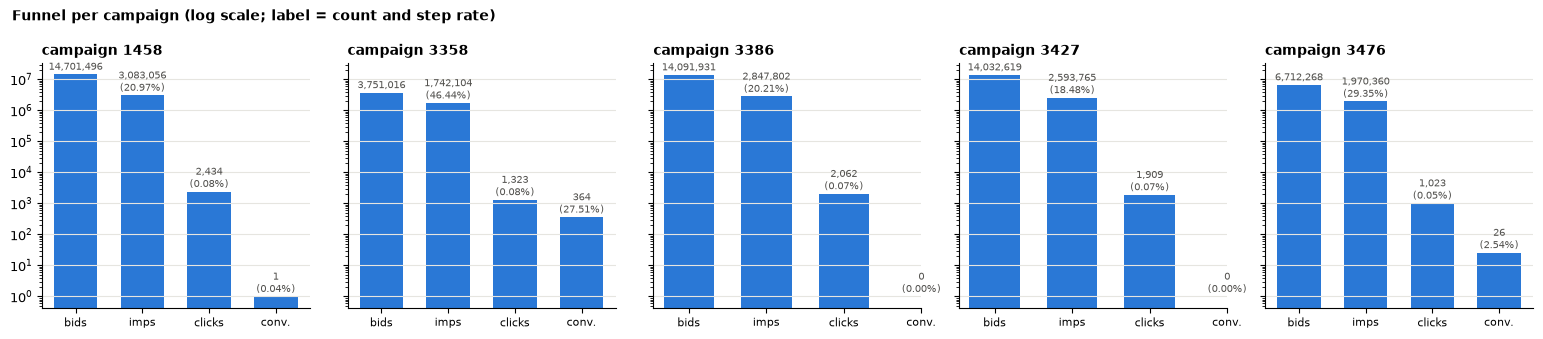

In [11]:
# CELL 5: funnel per campaign (every impression has an ad exchange, so summing that dimension gives campaign totals)
base = seg[seg.dimension == "ad_exchange"].groupby("scope")[["bids", "imps", "clicks", "pc_convs", "convs", "spend"]].sum()
base = base.loc[[s for s in base.index if s != "ALL"] + ["ALL"]]
FUN = pd.DataFrame(index=base.index)
FUN["bids"], FUN["imps"], FUN["clicks"], FUN["conversions"] = base.bids, base.imps, base.clicks, base.pc_convs
FUN["win_rate"] = FUN.imps / FUN.bids
FUN["ctr"] = FUN.clicks / FUN.imps
FUN["cvr"] = FUN.conversions / FUN.clicks.where(FUN.clicks > 0)
FUN["lost_auctions"] = FUN.bids - FUN.imps
FUN["unclicked_imps"] = FUN.imps - FUN.clicks
FUN["unconverted_clicks"] = FUN.clicks - FUN.conversions
FUN["bids_per_click"] = FUN.bids / FUN.clicks
FUN["bids_per_conversion"] = FUN.bids / FUN.conversions.where(FUN.conversions > 0)
FUN["spend_per_conversion"] = base.spend / base.convs.where(base.convs > 0)
display(FUN.style.format({"bids": "{:,.0f}", "imps": "{:,.0f}", "clicks": "{:,.0f}", "conversions": "{:,.0f}",
                          "win_rate": "{:.1%}", "ctr": "{:.3%}", "cvr": "{:.1%}", "lost_auctions": "{:,.0f}",
                          "unclicked_imps": "{:,.0f}", "unconverted_clicks": "{:,.0f}", "bids_per_click": "{:,.0f}",
                          "bids_per_conversion": "{:,.0f}", "spend_per_conversion": "{:,.0f}"}, na_rep="–"))

if plt:
    rows = [s for s in FUN.index if s != "ALL"]
    fig, axes = plt.subplots(1, len(rows), figsize=(3.1 * len(rows), 3.4), sharey=True)
    for ax, s in zip(np.atleast_1d(axes), rows):
        r = FUN.loc[s]
        vals = [r.bids, r.imps, r.clicks, r.conversions]
        ax.bar(range(4), [v if v > 0 else np.nan for v in vals], color=BLUE, width=0.65)
        ax.set_yscale("log")
        for x, (v, rate) in enumerate(zip(vals, [None, r.win_rate, r.ctr, r.cvr])):
            ax.text(x, max(v, 1) * 1.4, f"{v:,.0f}" + ("" if rate is None or rate != rate else f"\n({rate:.2%})"),
                    ha="center", fontsize=7, color=INK2)
        ax.set_xticks(range(4), ["bids", "imps", "clicks", "conv."], fontsize=8)
        ax.set_title(f"campaign {s}")
        ax.grid(axis="x", visible=False)
    fig.suptitle("Funnel per campaign (log scale; label = count and step rate)", x=0.01, ha="left",
                 fontweight="bold", fontsize=10)
    fig.tight_layout()
    save(fig, "07_funnel_per_campaign")
    plt.show()

### 6. Which segments lose the most, at each step?

The calculation runs for every segment of every dimension, within each campaign. User tags are left out, because one impression carries several tags, so their losses would be counted more than once. Segments under the minimum volume are skipped, using the same thresholds as Notebook 05: CTR needs ≥ 30 expected clicks, CVR ≥ 30 clicks and win rate ≥ 1,000 bids.

Columns:
* **input / output**: units entering and leaving the step
* **rate** vs **campaign rate**
* **shortfall**: units lost beyond the campaign average. Positive means the segment loses more than its share.
* **z**: shortfall in standard errors (|z| > 1.96 ≈ p < 0.05)
* **share of campaign loss** vs **share of campaign input**: if a segment gets 20% of the input but causes 35% of the losses, it is over-represented in the losses.

In [12]:
# CELL 6: shortfall per segment and step, within each campaign
STAGES = [("bid → impression", "bids", "imps", "show_wr"),
          ("impression → click", "imps", "clicks", "show_ctr"),
          ("click → conversion", "clicks", "pc_convs", "show_cvr")]
SEGS = S[(S.dimension != "user_tag") & (S.scope != "ALL")].copy()
camp = SEGS[SEGS.dimension == "ad_exchange"].groupby("scope")[["bids", "imps", "clicks", "pc_convs"]].sum()
rows = []
for stage, n_in, n_out, flag in STAGES:
    d = SEGS[SEGS[flag] & (SEGS[n_in] > 0)].copy()
    if d.empty:
        continue
    rate = d.scope.map(camp[n_out] / camp[n_in])
    d = d[rate > 0]
    rate = rate[d.index]
    d["stage"], d["input"], d["output"] = stage, d[n_in], d[n_out]
    d["rate"], d["campaign_rate"] = d.output / d.input, rate
    d["shortfall"] = d.input * rate - d.output
    d["shortfall_pct"] = d.shortfall / (d.input * rate)
    d["z"] = d.shortfall / np.sqrt(d.input * rate * (1 - rate))
    d["share_of_campaign_input"] = d.input / d.scope.map(camp[n_in])
    d["share_of_campaign_loss"] = (d.input - d.output) / d.scope.map(camp[n_in] - camp[n_out])
    rows.append(d)
LOSS = pd.concat(rows, ignore_index=True)
cols = ["scope", "dimension", "label", "input", "output", "rate", "campaign_rate", "shortfall", "shortfall_pct", "z",
        "share_of_campaign_input", "share_of_campaign_loss"]
F7 = {"input": "{:,.0f}", "output": "{:,.0f}", "shortfall": "{:+,.0f}", "shortfall_pct": "{:+.0%}", "z": "{:+.1f}",
      "share_of_campaign_input": "{:.1%}", "share_of_campaign_loss": "{:.1%}"}
for stage, *_ in STAGES:
    d = LOSS[(LOSS.stage == stage) & (LOSS.z > 1.96)].nlargest(12, "shortfall")
    rate_fmt = "{:.1%}" if stage != "impression → click" else "{:.3%}"
    display(Markdown(f"**{stage}: the segments that lose the most beyond their campaign's average** "
                     f"(z > 1.96, top 12 by units lost)"))
    if d.empty:
        print("none significantly above average")
    else:
        display(d[cols].style.format({**F7, "rate": rate_fmt, "campaign_rate": rate_fmt}).hide(axis="index"))

try:
    LOSS.to_csv(PROJECT_ROOT / "data" / "processed" / "funnel_dropoff.csv", index=False)
except OSError:
    pass

**bid → impression: the segments that lose the most beyond their campaign's average** (z > 1.96, top 12 by units lost)

scope,dimension,label,input,output,rate,campaign_rate,shortfall,shortfall_pct,z,share_of_campaign_input,share_of_campaign_loss
1458,slot_size,300x250,"6,911,217","212,902",3.1%,21.0%,"+1,236,452",+85%,+1155.3,47.0%,57.7%
1458,ad_exchange,3,"11,077,649","1,128,717",10.2%,21.0%,"+1,194,381",+51%,+881.5,75.4%,85.6%
3386,ad_exchange,3,"11,517,530","1,236,564",10.7%,20.2%,"+1,090,984",+47%,+800.6,81.7%,91.4%
1458,slot_visibility,0,"11,713,191","1,494,067",12.8%,21.0%,"+962,310",+39%,+690.7,79.7%,88.0%
3386,floor_band,d: 51-100,"7,503,010","576,692",7.7%,20.2%,"+939,572",+62%,+854.2,53.2%,61.6%
1458,floor_band,d: 51-100,"7,514,433","673,330",9.0%,21.0%,"+902,524",+57%,+808.7,51.1%,58.9%
3386,slot_visibility,0,"12,160,177","1,667,314",13.7%,20.2%,"+790,105",+32%,+564.2,86.3%,93.3%
1458,slot_format,0,"13,440,869","2,045,337",15.2%,21.0%,"+773,352",+27%,+518.2,91.4%,98.1%
3386,slot_size,300x250,"7,971,931","928,463",11.6%,20.2%,"+682,564",+42%,+602.0,56.6%,62.6%
3476,ad_exchange,3,"4,666,318","744,006",15.9%,29.4%,"+625,773",+46%,+636.1,69.5%,82.7%


**impression → click: the segments that lose the most beyond their campaign's average** (z > 1.96, top 12 by units lost)

scope,dimension,label,input,output,rate,campaign_rate,shortfall,shortfall_pct,z,share_of_campaign_input,share_of_campaign_loss
3386,slot_format,0,"2,176,840","1,220",0.056%,0.072%,+356,+23%,+9.0,76.4%,76.5%
3386,device,desktop,"2,767,640","1,657",0.060%,0.072%,+347,+17%,+7.8,97.2%,97.2%
3386,floor_band,c: 11-50,"753,462",201,0.027%,0.072%,+345,+63%,+14.8,26.5%,26.5%
3358,device,desktop,"1,649,278",947,0.057%,0.076%,+306,+24%,+8.6,94.7%,94.7%
3427,device,desktop,"2,519,724","1,581",0.063%,0.074%,+274,+15%,+6.4,97.1%,97.2%
1458,device,desktop,"2,984,940","2,117",0.071%,0.079%,+240,+10%,+4.9,96.8%,96.8%
3386,slot_visibility,2,"763,928",323,0.042%,0.072%,+230,+42%,+9.8,26.8%,26.8%
3427,browser,Chrome,"740,797",337,0.045%,0.074%,+208,+38%,+8.9,28.6%,28.6%
3427,ad_exchange,2,"905,346",460,0.051%,0.074%,+206,+31%,+8.0,34.9%,34.9%
3427,floor_band,c: 11-50,"531,092",187,0.035%,0.074%,+204,+52%,+10.3,20.5%,20.5%


**click → conversion: the segments that lose the most beyond their campaign's average** (z > 1.96, top 12 by units lost)

scope,dimension,label,input,output,rate,campaign_rate,shortfall,shortfall_pct,z,share_of_campaign_input,share_of_campaign_loss
3358,device,mobile,210,0,0.0%,27.5%,+58,+100%,+8.9,15.9%,21.9%
3358,browser,Safari,268,21,7.8%,27.5%,+53,+72%,+7.2,20.3%,25.8%
3358,os,Android,140,0,0.0%,27.5%,+39,+100%,+7.3,10.6%,14.6%
3358,slot_format,5,176,27,15.3%,27.5%,+21,+44%,+3.6,13.3%,15.5%
3358,os,iOS,226,46,20.4%,27.5%,+16,+26%,+2.4,17.1%,18.8%
3476,browser,IE,637,8,1.3%,2.5%,+8,+51%,+2.1,62.3%,63.1%


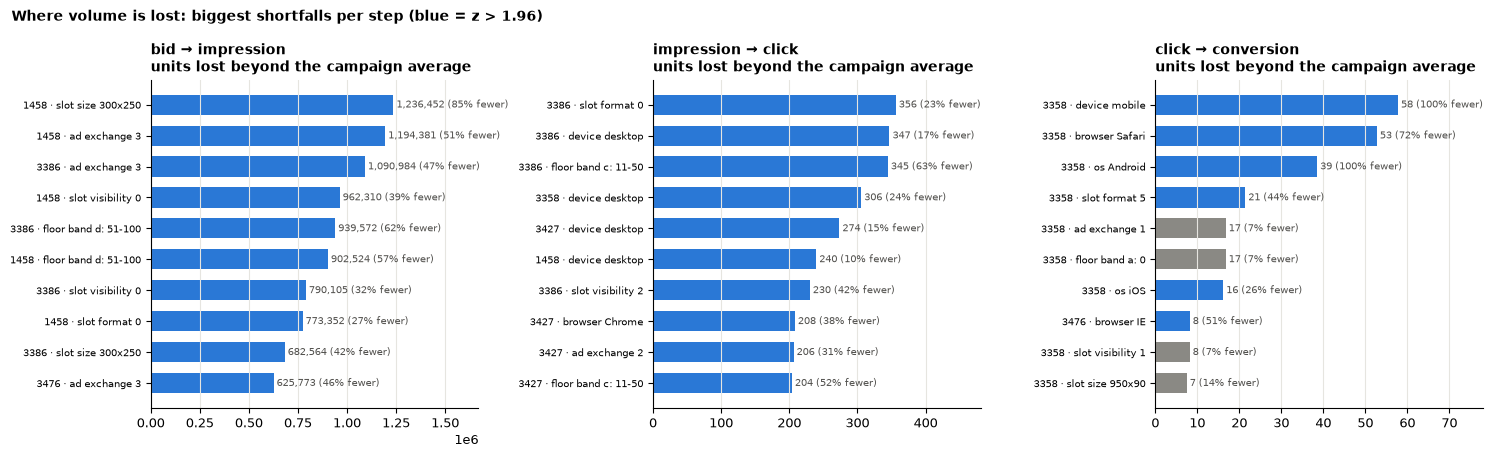

In [13]:
# CELL 7: charts - top shortfalls per step (campaign · dimension · segment)
if plt:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
    for ax, (stage, *_) in zip(axes, STAGES):
        d = LOSS[(LOSS.stage == stage) & (LOSS.shortfall > 0)].nlargest(10, "shortfall").iloc[::-1]
        if d.empty:
            ax.set_axis_off()
            continue
        y = np.arange(len(d))
        ax.barh(y, d.shortfall, color=np.where(d.z > 1.96, BLUE, GREY), height=0.65)
        ax.set_yticks(y, [f"{s} · {dim.replace('_', ' ')} {l[:18]}" for s, dim, l in zip(d.scope, d.dimension, d.label)],
                      fontsize=7.5)
        for yi, v, p in zip(y, d.shortfall, d.shortfall_pct):
            ax.text(v, yi, f" {v:,.0f} ({p:.0%} fewer)", va="center", fontsize=7, color=INK2)
        ax.set_xlim(right=d.shortfall.max() * 1.35)
        ax.grid(axis="y", visible=False)
        ax.set_title(f"{stage}\nunits lost beyond the campaign average")
    fig.suptitle("Where volume is lost: biggest shortfalls per step (blue = z > 1.96)", x=0.01, ha="left",
                 fontweight="bold", fontsize=10)
    fig.tight_layout()
    save(fig, "07_dropoff_segments")
    plt.show()

### 7. Which dimension explains the losses best?

For each dimension, the total **positive shortfall** across its segments measures how unevenly losses are spread over that dimension. If losses were spread evenly, every segment would sit at the average and this total would be near zero. The dimension with the largest total is where targeting or bidding changes would recover the most volume.

In [14]:
# CELL 8: losses concentrated by dimension
CONC = (LOSS[LOSS.shortfall > 0].groupby(["stage", "dimension"])
        .agg(units_lost_beyond_average=("shortfall", "sum"), segments_losing=("shortfall", "size"))
        .reset_index())
stage_lost = LOSS.groupby("stage").apply(lambda d: (d.input - d.output).sum() / d.dimension.nunique(), include_groups=False)
CONC["as_share_of_step_loss"] = CONC.units_lost_beyond_average / CONC.stage.map(stage_lost)
display(CONC.sort_values(["stage", "units_lost_beyond_average"], ascending=[True, False])
        .style.format({"units_lost_beyond_average": "{:,.0f}", "as_share_of_step_loss": "{:.1%}"}).hide(axis="index"))

stage,dimension,units_lost_beyond_average,segments_losing,as_share_of_step_loss
bid → impression,ad_exchange,"3,566,964",6,8.7%
bid → impression,floor_band,"3,300,985",12,8.0%
bid → impression,slot_size,"3,081,872",18,7.5%
bid → impression,slot_visibility,"2,402,328",7,5.9%
bid → impression,slot_format,"2,132,242",6,5.2%
bid → impression,region,"1,374,123",78,3.3%
bid → impression,browser,"728,458",23,1.8%
bid → impression,os,"352,961",22,0.9%
bid → impression,device,"119,643",8,0.3%
click → conversion,browser,67,9,1.6%


## Findings

Generated from the numbers above.

In [15]:
# CELL 9: findings + story candidates
a = FUN.loc["ALL"]
tot_loss = a.lost_auctions + a.unclicked_imps + a.unconverted_clicks
top = {st: LOSS[(LOSS.stage == st) & (LOSS.z > 1.96)].nlargest(1, "shortfall") for st, *_ in STAGES}
best_dim = {st: CONC[CONC.stage == st].nlargest(1, "units_lost_beyond_average") for st, *_ in STAGES}
F = [f"**The funnel (all campaigns):** {a.bids:,.0f} bids → {a.imps:,.0f} impressions ({a.win_rate:.1%}) → "
     f"{a.clicks:,.0f} clicks ({a.ctr:.3%}) → {a.conversions:,.0f} post-click conversions"
     + (f" ({a.cvr:.1%})" if a.cvr == a.cvr else "") + f". It takes about {a.bids_per_click:,.0f} bids to get one click.",
     f"**Where units are lost:** lost auctions are {a.lost_auctions / tot_loss:.1%} of all lost units, unclicked "
     f"impressions {a.unclicked_imps / tot_loss:.1%}, unconverted clicks {a.unconverted_clicks / tot_loss:.3%}. The "
     "biggest leak by count is the auction. The costliest is the click, because every unclicked impression was paid for."]
for st, d in top.items():
    if len(d):
        r = d.iloc[0]
        dimtxt = (f" The dimension with the most uneven losses at this step is **{best_dim[st].iloc[0].dimension.replace('_', ' ')}**."
                  if len(best_dim[st]) else "")
        F.append(f"**{st}: biggest loss** in campaign {r.scope}, {r.dimension.replace('_', ' ')} {r.label}: "
                 f"{r.shortfall:,.0f} fewer than at the campaign average ({r.shortfall_pct:.0%} fewer, z = {r.z:.1f})"
                 + (f"; it gets {r.share_of_campaign_input:.0%} of the input but causes {r.share_of_campaign_loss:.0%} of the losses"
                    if abs(r.share_of_campaign_loss - r.share_of_campaign_input) >= 0.01 else "") + "." + dimtxt)
F.append("**Caveat:** a shortfall says *where* volume leaks, not *why*. The segment may simply attract less engaged "
         "users. Test a bid change before cutting it.")
display(Markdown("\n".join(f"{i}. {t}" for i, t in enumerate(F, 1))))

cands = [{"title": f"It takes {a.bids_per_click:,.0f} bids to get one click",
          "number": f"{a.bids:,.0f} bids → {a.imps:,.0f} impressions ({a.win_rate:.1%} win rate) → {a.clicks:,.0f} clicks "
                    f"({a.ctr:.3%} CTR) → {a.conversions:,.0f} post-click conversions",
          "chart": "07_funnel_per_campaign.png", "confidence": "High (exact counts)",
          "meaning": "Most volume is lost in the auction, but the impressions nobody clicks are the paid loss. "
                     "Improving CTR is the cheapest way to lower cost per click."}]
r = top["impression → click"]
if len(r):
    r = r.iloc[0]
    cands.append({"title": f"Campaign {r.scope}: {r.dimension.replace('_', ' ')} {r.label} loses the most clicks",
                  "number": f"{r.shortfall:,.0f} fewer clicks than at the campaign's average CTR "
                            f"({r.rate:.3%} vs {r.campaign_rate:.3%}, on {r.input:,.0f} impressions)",
                  "chart": "07_dropoff_segments.png",
                  "confidence": "High (z = %.1f)" % r.z if r.z > 3.29 else "Medium (z = %.1f)" % r.z,
                  "meaning": "Lower the bid or exclude this segment in a test, and move the budget to segments that click "
                             "above average."})
save_story("07_funnel_dropoff", cands)

1. **The funnel (all campaigns):** 53,289,330 bids → 12,237,087 impressions (23.0%) → 8,751 clicks (0.072%) → 391 post-click conversions (4.5%). It takes about 6,090 bids to get one click.
2. **Where units are lost:** lost auctions are 77.0% of all lost units, unclicked impressions 22.9%, unconverted clicks 0.016%. The biggest leak by count is the auction. The costliest is the click, because every unclicked impression was paid for.
3. **bid → impression: biggest loss** in campaign 1458, slot size 300x250: 1,236,452 fewer than at the campaign average (85% fewer, z = 1155.3); it gets 47% of the input but causes 58% of the losses. The dimension with the most uneven losses at this step is **ad exchange**.
4. **impression → click: biggest loss** in campaign 3386, slot format 0: 356 fewer than at the campaign average (23% fewer, z = 9.0). The dimension with the most uneven losses at this step is **floor band**.
5. **click → conversion: biggest loss** in campaign 3358, device mobile: 58 fewer than at the campaign average (100% fewer, z = 8.9); it gets 16% of the input but causes 22% of the losses. The dimension with the most uneven losses at this step is **browser**.
6. **Caveat:** a shortfall says *where* volume leaks, not *why*. The segment may simply attract less engaged users. Test a bid change before cutting it.

Saved 2 story candidate(s) to reports/findings/07_funnel_dropoff.json
